Aula 03 - Pós Data Science e Big Data - Exploração dos dados
Objetivos: Detectar problemas de qualidade dos dados, preparar os dados para modelos de Machine Learning, treinar uma Árvore de Decisão, intepretar métricas e aplicar um segundo classificador ao conceito de eficiência energética


In [ ]:
# Importando bibliotecas
import numpy as np # permite trabalhar com array
import pandas as pd # permite importar a base de dados
import matplotlib.pyplot as plt # Permite plotar gráficos
from sklearn.model_selection import train_test_split # Permite dividir a base de dados em treino e teste
from sklearn.impute import SimpleImputer # Permite tratar dados ausentes na base de dados
from sklearn.pipeline import Pipeline # Permite criar um fluxo nas etapa de analise de dados
from sklearn.compose import ColumnTransformer # Permite aplicar transformações de dados diferentes para colunas diferentes
from sklearn.preprocessing import OneHotEncoder # Permite converter variáveis categóricas em um forma numérico para que os modelos de Machine Learning entendam
from sklearn.tree import DecisionTreeClassifier, plot_tree #Importa o modelo de árvore de decisao
from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score,classification_report, ConfusionMatrixDisplay)
import seaborn as sns

In [ ]:
# Importando a base de dados
df = pd.read_csv('consumo_energetico_alunos.csv')

In [ ]:
df.head()

,timestamp,turno,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,consumo_kwh
0,2026-10-12 22:00:00,noite,1102.0,21.80,7.0,4.86,283.36
1,2027-11-15 14:00:00,tarde,1356.0,21.31,6.0,6.90,335.73
2,2028-12-27 06:00:00,manha,796.0,28.89,3.0,6.74,197.15
3,2027-04-25 14:00:00,tarde,1406.0,22.52,7.0,6.05,291.80
4,2028-03-27 06:00:00,manha,1431.0,23.98,7.0,5.44,269.41


In [ ]:
print(f"Quantidade de linhas {len(df)} | Quantidade de colunas {len(df.columns)}")


Quantidade de linhas 5050 | Quantidade de colunas 8


In [ ]:
# Exploração dos dados
'''
Quantas linhas e colunas ? Quais variáveis são numéricas ? Quais são as classes de turno ? Há dados ausentes e repetidos ?
'''
print("Tipos de dados")
print(df.dtypes) # Exibe os tipos de dados das colunas
print('\n Ausentes')
print(df.isna().sum()) # Verificando dados ausentes
print('\n Duplicados: ',df.duplicated().sum()) # Verificando dados duplicados
print("\n Distribuição de turnos")
print(df['turno'].value_counts())
display(df.select_dtypes(include="number").describe().round(2))

Tipos de dados
timestamp                  object
turno                      object
producao_unidades         float64
temperatura_ambiente_c    float64
maquinas_ativas           float64
horas_operacao_turno      float64
consumo_kwh               float64
dtype: object

 Ausentes
timestamp                  0
turno                      0
producao_unidades         51
temperatura_ambiente_c    50
maquinas_ativas           50
horas_operacao_turno      51
consumo_kwh                0
dtype: int64

 Duplicados:  50

 Distribuição de turnos
turno
manha    1685
tarde    1683
noite    1682
Name: count, dtype: int64


,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,consumo_kwh
count,4999.00,5000.00,5000.00,4999.00,5050.00
mean,1902.49,26.33,8.97,5.99,399.25
std,940.45,6.21,3.74,1.16,176.52
min,311.00,14.00,3.00,4.00,71.97
25%,1152.00,23.01,6.00,4.98,252.84
50%,1821.00,26.12,9.00,5.99,384.32
75%,2505.00,29.21,12.00,6.99,519.82
max,11239.63,124.86,15.00,8.00,884.82


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               5050 non-null   object 
 1   turno                   5050 non-null   object 
 2   producao_unidades       4999 non-null   float64
 3   temperatura_ambiente_c  5000 non-null   float64
 4   maquinas_ativas         5000 non-null   float64
 5   horas_operacao_turno    4999 non-null   float64
 6   consumo_kwh             5050 non-null   float64
dtypes: float64(5), object(2)
memory usage: 276.3+ KB


# Limpeza e análise de outliers
Remova duplicatas exatas; mantenha um registro de quantas foram removidas.
Converta datas sem usá-las diretamente como preditores nesta introdução.
Investigue valores improváveis antes de removê-los. O limite de 50 °C para temperatura ambiente é apenas uma regra didática de sinalização, não uma especificação do processo.
Importante: valores ausentes dos preditores serão preenchidos com medianas aprendidas somente no treinamento, via Pipeline. Não calcular fillna(median()) no dataset completo antes do split.

In [ ]:
# Limpeza e análise de outliers
df1 =df.drop_duplicates().copy() # varre o dataframe em busca de valores duplicados
df['timestamp'] = pd.to_datetime(df['timestamp'],errors='coerce')
print('Removidas:', len(df)-len(df1),"duplicadas")
print('Datas inválidas:', df['timestamp'].isna().sum())
print('Temperaturas acima de 50 ºC para investigar:',(df['temperatura_ambiente_c']>50).sum())
print('Consumo<=0',(df["consumo_kwh"]<=0).sum())


Removidas: 50 duplicadas
Datas inválidas: 0
Temperaturas acima de 50 ºC para investigar: 25
Consumo<=0 0


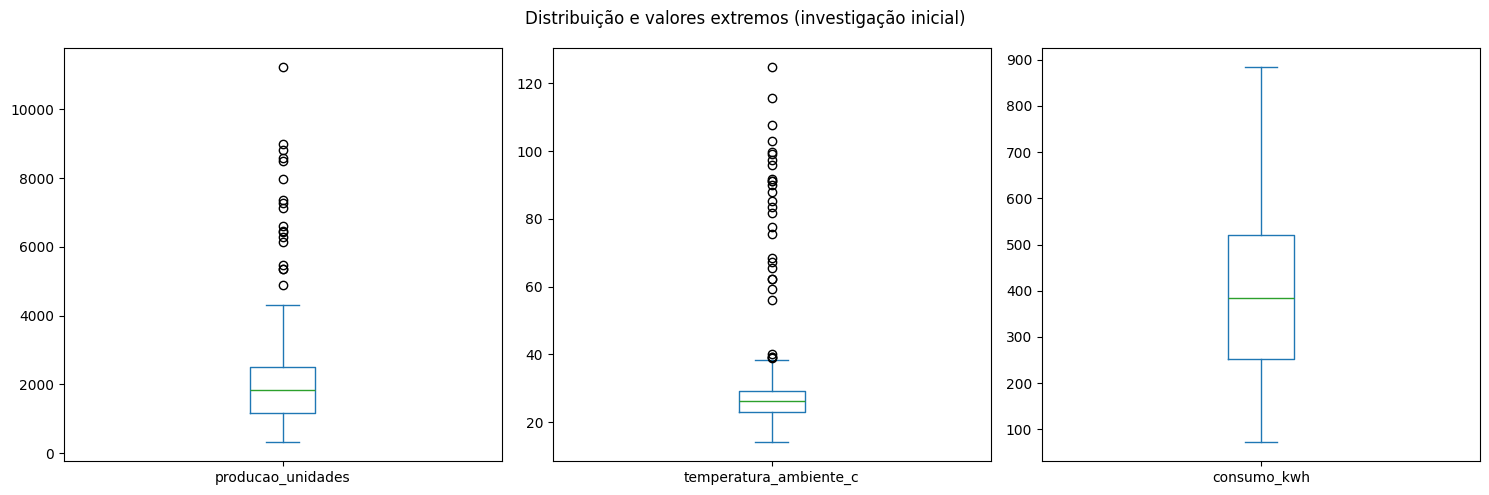

In [ ]:
#Visualização
df[['producao_unidades','temperatura_ambiente_c','consumo_kwh']].plot(kind='box',subplots=True,layout=(1,3),figsize=(15,5),sharey=False)
plt.suptitle('Distribuição e valores extremos (investigação inicial)')
plt.tight_layout()
plt.show()

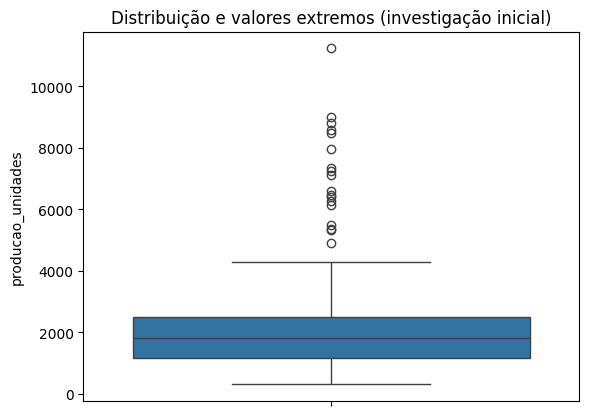

In [ ]:
sns.boxplot(data=df['producao_unidades'])
plt.title('Distribuição e valores extremos (investigação inicial)')
plt.show()

Introdução ao aprendizado supervisionado - Prever uma classe consumo alto ou baixo - Classificação: prever uma classe (consumo alto ou baixo).
- Regressão: prever um número (ex.: kWh).
- Supervisionado: o rótulo correto está disponível durante o treino.
- Não supervisionado: buscamos padrões sem rótulos previamente definidos.
Nesta atividade, alto consumo significa consumo_kwh > 400, e baixo significa <= 400. 400 kWh é um limite DIDÁTICO, não um critério de desempenho industrial. Na entrada do modelo, nunca incluir consumo_kwh, porque ele é a própria origem do rótulo.

consumo_alto
Baixo    2666
Alto     2384
Name: count, dtype: int64


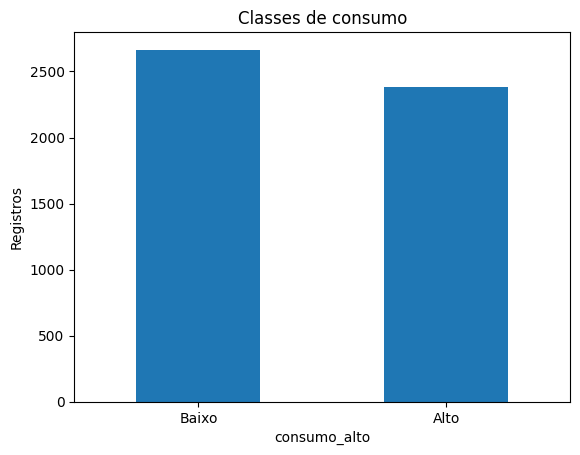

In [ ]:
# Consumo é medido e serve apenas para criar o rótulo histórico
assert df["consumo_kwh"].notna().all()
df["consumo_alto"] = (df["consumo_kwh"] > 400).astype(int)
print(df["consumo_alto"].value_counts().rename(index={0:"Baixo",1:"Alto"}))
df["consumo_alto"].map({0:"Baixo",1:"Alto"}).value_counts().plot(kind="bar", title="Classes de consumo")
plt.xticks(rotation=0); plt.ylabel("Registros"); plt.show()

Separar os atributos, treinar e prever
Os preditores numéricos são produção, temperatura, máquinas ativas e horas de operação; turno é categórico. O ColumnTransformer aplica medianas aos dados numéricos e codifica o turno; o Pipeline aprende tudo sem acessar os valores do conjunto de teste.

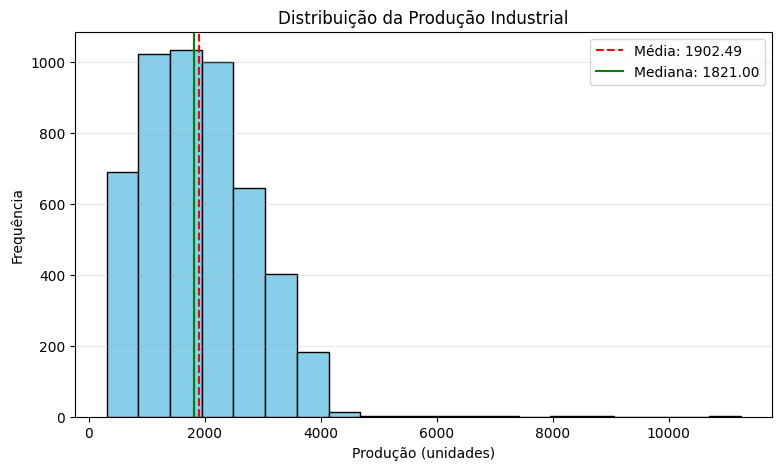

In [ ]:
import matplotlib.pyplot as plt

# Seleciona a variável
dados = df["producao_unidades"].dropna()

# Calcula média e mediana
media = dados.mean()
mediana = dados.median()

# Plota o histograma
plt.figure(figsize=(9, 5))

plt.hist(
    dados,
    bins=20,
    color="skyblue",
    edgecolor="black"
)

# Linha indicando a média
plt.axvline(
    media,
    color="red",
    linestyle="--",
    label=f"Média: {media:.2f}"
)

# Linha indicando a mediana
plt.axvline(
    mediana,
    color="green",
    linestyle="-",
    label=f"Mediana: {mediana:.2f}"
)

plt.title("Distribuição da Produção Industrial")
plt.xlabel("Produção (unidades)")
plt.ylabel("Frequência")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

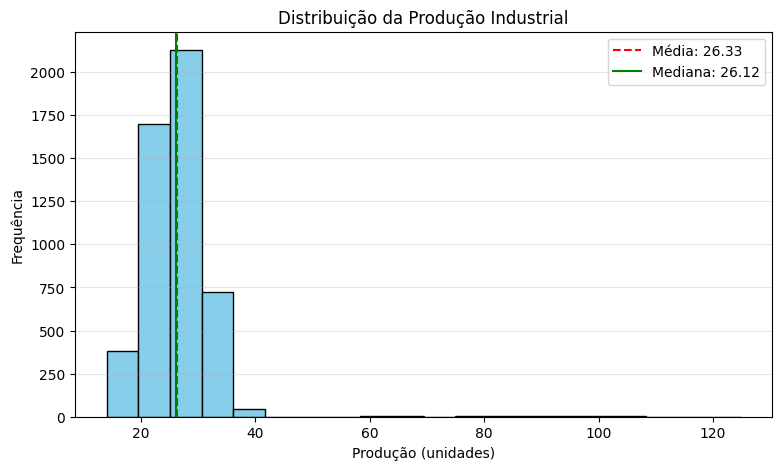

In [ ]:
import matplotlib.pyplot as plt

# Seleciona a variável
dados = df["temperatura_ambiente_c"].dropna()

# Calcula média e mediana
media = dados.mean()
mediana = dados.median()

# Plota o histograma
plt.figure(figsize=(9, 5))

plt.hist(
    dados,
    bins=20,
    color="skyblue",
    edgecolor="black"
)

# Linha indicando a média
plt.axvline(
    media,
    color="red",
    linestyle="--",
    label=f"Média: {media:.2f}"
)

# Linha indicando a mediana
plt.axvline(
    mediana,
    color="green",
    linestyle="-",
    label=f"Mediana: {mediana:.2f}"
)

plt.title("Distribuição da Produção Industrial")
plt.xlabel("Produção (unidades)")
plt.ylabel("Frequência")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# Comparação das medidas estatísticas
resumo = pd.DataFrame({
    "Média": df[numericas].mean(),
    "Mediana": df[numericas].median(),
    "Valores ausentes": df[numericas].isnull().sum()
})

print(resumo.round(2))

                          Média  Mediana  Valores ausentes
producao_unidades       1902.49  1821.00                51
temperatura_ambiente_c    26.33    26.12                50
maquinas_ativas            8.97     9.00                50
horas_operacao_turno       5.99     5.99                51


In [ ]:
numericas = ["producao_unidades", "temperatura_ambiente_c", "maquinas_ativas", "horas_operacao_turno"]
categoricas = ["turno"]
atributos = numericas + categoricas
X = df[atributos]
y = df["consumo_alto"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

preprocessamento = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])
modelo_consumo = Pipeline([
    ("preparacao", preprocessamento),
    ("arvore", DecisionTreeClassifier(max_depth=4, random_state=42))
])
modelo_consumo.fit(X_treino, y_treino)
previsoes = modelo_consumo.predict(X_teste)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))

Treino: 4040 | Teste: 1010


Avaliação do primeiro modelo
Acurácia: proporção de previsões corretas. Precisão da classe alta: entre os turnos previstos como alto consumo, quantos de fato foram altos? Recall da classe alta: entre os turnos de alto consumo, quantos foram identificados? F1: equilíbrio entre precisão e recall.
Uma matriz de confusão mostra acertos e erros. Em problemas reais, discuta qual tipo de erro é mais caro.


== Consumo ALTO/BAIXO ==
Acurácia: 0.969
Precisão (classe 1): 0.974
Recall (classe 1): 0.960
F1 (classe 1): 0.967
              precision    recall  f1-score   support

       Baixo       0.96      0.98      0.97       533
        Alto       0.97      0.96      0.97       477

    accuracy                           0.97      1010
   macro avg       0.97      0.97      0.97      1010
weighted avg       0.97      0.97      0.97      1010



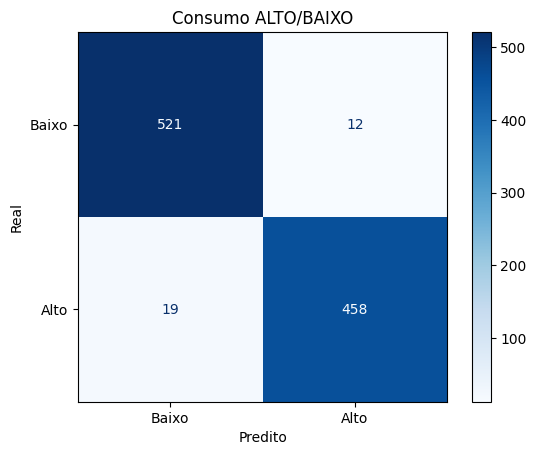

In [ ]:
def avaliar(nome, verdadeiro, previsto, rotulos=("Baixo", "Alto")):
    print(f"\n== {nome} ==")
    print(f"Acurácia: {accuracy_score(verdadeiro, previsto):.3f}")
    print(f"Precisão (classe 1): {precision_score(verdadeiro, previsto, zero_division=0):.3f}")
    print(f"Recall (classe 1): {recall_score(verdadeiro, previsto, zero_division=0):.3f}")
    print(f"F1 (classe 1): {f1_score(verdadeiro, previsto, zero_division=0):.3f}")
    print(classification_report(verdadeiro, previsto, target_names=rotulos, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(verdadeiro, previsto, display_labels=rotulos, cmap="Blues")
    plt.title(nome)
    plt.xlabel('Predito')
    plt.ylabel('Real')
    plt.show()

avaliar("Consumo ALTO/BAIXO", y_teste, previsoes)

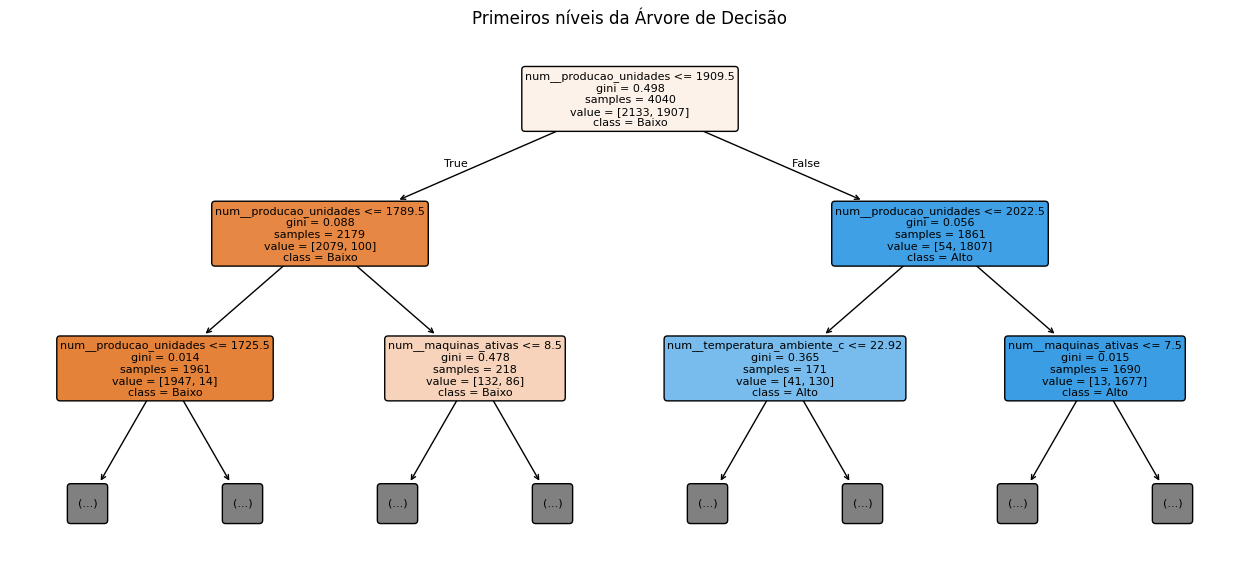

In [ ]:
# Visualização opcional: primeiros níveis da árvore
nomes = modelo_consumo.named_steps["preparacao"].get_feature_names_out()
plt.figure(figsize=(16,7))
plot_tree(modelo_consumo.named_steps["arvore"],
          feature_names=nomes, class_names=["Baixo", "Alto"],
          filled=True, rounded=True, fontsize=8, max_depth=2)
plt.title("Primeiros níveis da Árvore de Decisão"); plt.show()

### Segundo Classificador: Random Forest

Agora vamos treinar um modelo de **Random Forest** utilizando os mesmos dados de treino e a mesma estrutura de pré-processamento via `Pipeline`. Após o treinamento, utilizaremos a função `avaliar` para comparar as métricas com as da nossa primeira Árvore de Decisão.


== Consumo ALTO/BAIXO (Random Forest) ==
Acurácia: 0.971
Precisão (classe 1): 0.967
Recall (classe 1): 0.973
F1 (classe 1): 0.970
              precision    recall  f1-score   support

       Baixo       0.98      0.97      0.97       533
        Alto       0.97      0.97      0.97       477

    accuracy                           0.97      1010
   macro avg       0.97      0.97      0.97      1010
weighted avg       0.97      0.97      0.97      1010



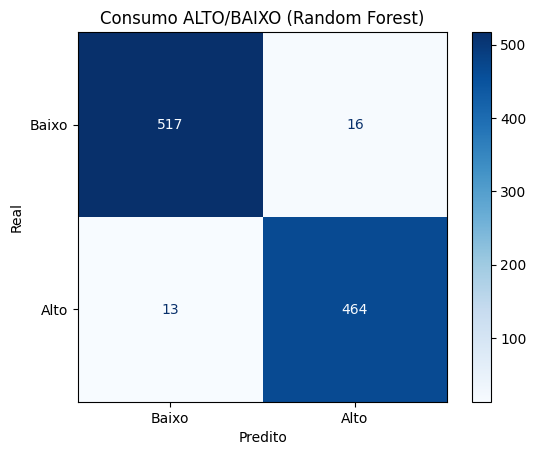

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Criando o Pipeline com o preprocessamento existente e o classificador Random Forest
modelo_rf = Pipeline([
    ("preparacao", preprocessamento),
    ("floresta", RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

# Treinando o modelo
modelo_rf.fit(X_treino, y_treino)

# Fazendo as previsões no conjunto de teste
previsoes_rf = modelo_rf.predict(X_teste)

# Avaliando o desempenho do Random Forest
avaliar("Consumo ALTO/BAIXO (Random Forest)", y_teste, previsoes_rf)